# [오늘의 과제] 따릉이 대여 데이터 - 기초 EDA 리포트


# 0. 환경 준비

In [8]:
!pip install numpy pandas seaborn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 12.8 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 19.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 14.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 18.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [seaborn]m8/9 [seaborn]ib]


In [9]:
# ─────────────────────────────────────────────
# 환경 준비 — 라이브러리 불러오기 + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
# !pip install numpy pandas matplotlib seaborn -q

import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")   # 학습 중 경고 메시지를 잠시 숨깁니다.

# 재현성: 같은 난수를 항상 같게 만들어 결과가 매번 동일하도록 고정합니다.
np.random.seed(42)

# 한글 폰트 설정 (그래프 안 글자가 깨지지 않도록 운영체제별로 분기)
system = platform.system()
if system == "Darwin":          # macOS
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":       # Windows
    plt.rcParams["font.family"] = "Malgun Gothic"
else:                            # Linux 등
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.unicode_minus"] = False   # 마이너스 부호 깨짐 방지
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

print("준비 완료! 라이브러리 버전을 확인합니다.")
print("numpy :", np.__version__)
print("pandas:", pd.__version__)

준비 완료! 라이브러리 버전을 확인합니다.
numpy : 2.5.4
pandas: 3.0.6


## 1. 데이터 개요
- 행/열: (181행, 5열)
- 기간: 2025-01-01 ~ 2025-06-29
- 주요 컬럼: date, rentals, avg_temp, rainfall, station_area

In [16]:
# 공공데이터 스타일 데이터 생성 (따릉이 일별 대여 기록 — 가상)
np.random.seed(7)
n_days = 180
dates = pd.date_range("2025-01-01", periods=n_days, freq="D")
# 계절성: 봄·여름에 대여 증가
seasonal = 3000 + 2500 * np.sin(np.linspace(0, np.pi, n_days))
rentals = (seasonal + np.random.normal(0, 400, n_days)).round().astype(int)

bike = pd.DataFrame({
    "date": dates,
    "rentals": rentals,
    "avg_temp": (np.linspace(-2, 28, n_days) + np.random.normal(0, 2, n_days)).round(1),
    "rainfall": np.random.choice([0, 0, 0, 0, 5, 12, 30], n_days),
    "station_area": np.random.choice(["강남", "마포", "송파", "종로", " 강남 "], n_days),
})
# 오염 심기: 대여수 결측, 기온 이상치, 중복 행
bike.loc[np.random.choice(n_days, 8, replace=False), "rentals"] = np.nan
bike.loc[50, "avg_temp"] = 250.0     # 센서 오류로 보이는 이상치
bike = pd.concat([bike, bike.iloc[[3]]], ignore_index=True)  # 중복 1건

print("따릉이 데이터 준비 완료:", bike.shape)
bike.head()

따릉이 데이터 준비 완료: (181, 5)


,date,rentals,avg_temp,rainfall,station_area
0,2025-01-01,3676.0,-3.0,12,마포
1,2025-01-02,2857.0,-1.1,0,마포
2,2025-01-03,3101.0,-1.1,0,강남
3,2025-01-04,3295.0,0.9,0,강남
4,2025-01-05,2860.0,-1.1,0,마포


## 2. 구조 진단 (shape / info / describe)
- 자료형 요약: (날짜 열은 datetime으로 인식됨 / ...)
- 수치 요약에서 눈에 띈 점: (rentals 평균 4531.757225, avg_temp 최댓값 250 → 이상치 의심)


In [27]:
bike.info()

<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          181 non-null    datetime64[us]
 1   rentals       173 non-null    float64       
 2   avg_temp      181 non-null    float64       
 3   rainfall      181 non-null    int64         
 4   station_area  181 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 7.2 KB


In [28]:
bike.describe()

,date,rentals,avg_temp,rainfall
count,181,173.000000,181.000000,181.000000
mean,2025-03-31 00:31:49.392265,4531.757225,14.169061,5.298343
min,2025-01-01 00:00:00,2514.000000,-4.900000,0.000000
25%,2025-02-14 00:00:00,3841.000000,5.100000,0.000000
50%,2025-03-31 00:00:00,4708.000000,13.100000,0.000000
75%,2025-05-15 00:00:00,5243.000000,20.600000,5.000000
max,2025-06-29 00:00:00,6388.000000,250.000000,30.000000
std,NaN,889.609013,19.742786,9.687303


## 3. 품질 진단 (결측 / 중복 / 표기)
- 결측: rentals 8건
- 중복: 1건
- 표기 혼재: station_area에 ' 강남 '(공백) 존재
- 기온 이상치 확인: 상위 3개 출력하여 '250' 확인

In [36]:
print("[결측치]")
print(bike.isnull().sum())
print("\n중복 행:", bike.duplicated().sum())
print("\n[station_area 값의 종류]")
print(bike["station_area"].unique())
print("\n기온 이상치 확인(상위 3개):")
print(bike["avg_temp"].sort_values(ascending=False).head(3).tolist())

[결측치]
date            0
rentals         8
avg_temp        0
rainfall        0
station_area    0
dtype: int64

중복 행: 1

[station_area 값의 종류]
<StringArray>
['마포', ' 강남 ', '강남', '송파', '종로']
Length: 5, dtype: str

기온 이상치 확인(상위 3개):
[250.0, 31.8, 30.6]


## 4. 패턴 (시각화에서 읽은 것)
- 추이: (계절성 — 봄~여름 증가 등)
- 관계: (기온과 대여 수의 양의 관계 등)


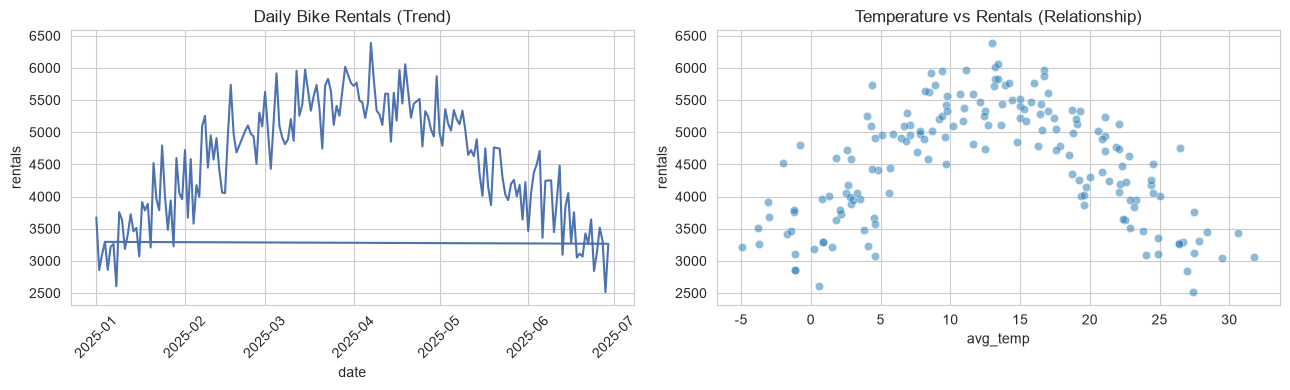

In [38]:
# 시각화 (이상치 제거 후: 시각화 목적에 맞는 기온 이상치, 결측치만 처리함)
clean = bike[(bike["avg_temp"] < 60)].dropna(subset=["rentals"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# 추이
axes[0].plot(clean["date"], clean["rentals"], color="#4C72B0")
axes[0].set_title("Daily Bike Rentals (Trend)")
axes[0].set_xlabel("date"); axes[0].set_ylabel("rentals")
axes[0].tick_params(axis="x", rotation=45)
# 관계
sns.scatterplot(data=clean, x="avg_temp", y="rentals", alpha=0.5, ax=axes[1])
axes[1].set_title("Temperature vs Rentals (Relationship)")
axes[1].set_xlabel("avg_temp"); axes[1].set_ylabel("rentals")
plt.tight_layout(); plt.show()

## 5. 다음 분석 제안
- (이상치/결측을 어떻게 처리할지, 추가로 보고 싶은 것)

### 5.1. 대여량 결측 처리 방법 고민
- 핵심 변수라서 평균값, 중앙값으로 대체하기보다는 삭제가 맞다고 판단함
- 단, 전체 데이터 중 결측치가 차지하는 비율 확인한 뒤 최종 결정

In [39]:
miss = df["rentals"].isnull()
print("결측 비율:", round(miss.mean() * 100, 1), "%")
print(df.groupby(miss)["avg_temp"].describe())   # 결측인 날 vs 아닌 날의 기온 비교
print(df[miss]["date"].dt.month.value_counts().sort_index())  # 특정 달에 몰려 있는지

결측 비율: 4.4 %
         count       mean        std  min     25%    50%    75%    max
rentals                                                               
False    173.0  14.110983  20.150681 -4.9   4.600  13.10  20.60  250.0
True       8.0  15.425000   6.613568  5.5  11.175  14.85  20.15   24.3
date
2    1
3    3
4    2
5    1
6    1
Name: count, dtype: int64


대여량 결측은 전체의 4.4%(8건)이며, 결측일의 기온 분포(중앙값 14.85)가 관측일(중앙값 13.1)과 유사하고 특정 월에 집중되지 않아 무작위 결측으로 판단해 삭제 처리함.

### 5.2. 지역 컬럼 정리


In [40]:
print("[정리 전]\n", df["station_area"].value_counts(dropna=False))

df["station_area"] = df["station_area"].str.strip()
area_map = {}   # ← 위 출력 보고 채우기. 예: {"강남": "강남구", "gangnam": "강남구"}
df["station_area"] = df["station_area"].replace(area_map).fillna("미상")

print("\n[정리 후]\n", df["station_area"].value_counts())

[정리 전]
 station_area
강남      44
마포      37
송파      37
 강남     34
종로      29
Name: count, dtype: int64

[정리 후]
 station_area
강남    78
마포    37
송파    37
종로    29
Name: count, dtype: int64


### 5.3. 중복 행 제거 + 최종 정제 

In [41]:
before = len(df)
df = df.drop_duplicates()
print(f"중복 제거: {before} → {len(df)}행 ({before - len(df)}건 제거)")
print("같은 날짜 반복:", df["date"].duplicated().sum())   # 0이 아니면 알려주세요

clean = df[df["avg_temp"] < 60].dropna(subset=["rentals"])
print("최종 분석 행 수:", len(clean))

중복 제거: 181 → 180행 (1건 제거)
같은 날짜 반복: 0
최종 분석 행 수: 171


### 5.4. 지역별 시각화 

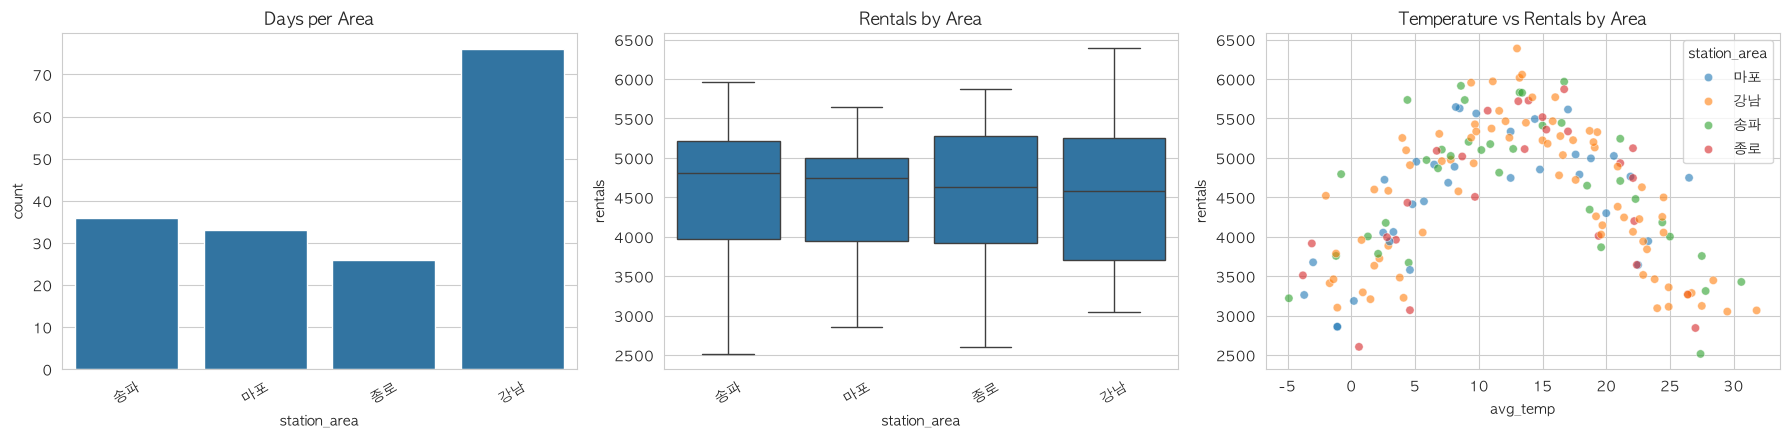

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
order = clean.groupby("station_area")["rentals"].median().sort_values(ascending=False).index

sns.countplot(data=clean, x="station_area", order=order, ax=axes[0])
axes[0].set_title("Days per Area")

sns.boxplot(data=clean, x="station_area", y="rentals", order=order, ax=axes[1])
axes[1].set_title("Rentals by Area")

sns.scatterplot(data=clean, x="avg_temp", y="rentals", hue="station_area", alpha=0.6, ax=axes[2])
axes[2].set_title("Temperature vs Rentals by Area")

for ax in axes[:2]: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [46]:
summary = clean.groupby("station_area")["rentals"].agg(["count", "median", "mean"]).round(1)
summary["temp_corr"] = clean.groupby("station_area").apply(lambda g: g["avg_temp"].corr(g["rentals"])).round(2)
print(summary.sort_values("median", ascending=False))
print("\n전체 기온-대여량 상관계수:", round(clean["avg_temp"].corr(clean["rentals"]), 2))

              count  median    mean  temp_corr
station_area                                  
송파               36  4803.5  4642.4      -0.20
마포               33  4746.0  4503.7       0.47
종로               26  4625.5  4504.2       0.17
강남               76  4579.5  4502.0      -0.14

전체 기온-대여량 상관계수: -0.0


          count  median
temp_bin               
(-10, 0]     14  3486.0
(0, 5]       30  3960.0
(5, 10]      28  5022.0
(10, 15]     27  5465.0
(15, 20]     29  5132.0
(20, 25]     30  4212.0
(25, 35]     13  3270.0


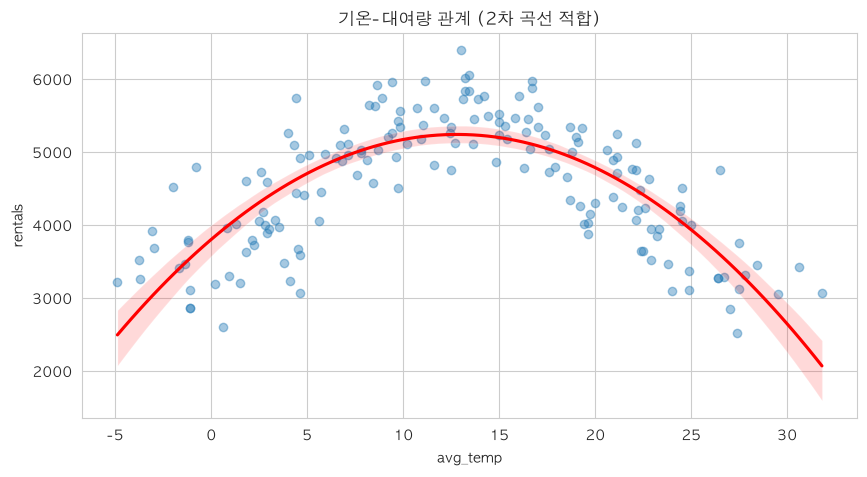

In [47]:
clean["temp_bin"] = pd.cut(clean["avg_temp"], bins=[-10, 0, 5, 10, 15, 20, 25, 35])
print(clean.groupby("temp_bin", observed=True)["rentals"].agg(["count", "median"]).round(0))

sns.regplot(data=clean, x="avg_temp", y="rentals", order=2,
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("기온-대여량 관계 (2차 곡선 적합)"); plt.show()

- 기온과 대여량은 직선이 아닌 뒤집힌 U자 관계를 보임. 
- 대여량 중앙값은 10~15℃ 구간에서 5,465로 가장 높고, 
<br> 0℃ 이하(3,486)와 25℃ 초과(3,270) 구간에서는 약 40% 낮음. 
<br> n2차 곡선 적합 결과 약 13℃ 부근에서 대여량이 최대로 나타남.
- 오르막과 내리막이 상쇄되어 전체 상관계수는 -0.0으로 나타나므로, 상관계수만으로는 관계를 판단할 수 없음

### 5.5 데이터 정제 및 지역별 분석 요약

**정제 내역**
- 지역 표기 통일: 앞 공백이 포함된 " 강남"(34건)을 공백 제거로 "강남"(44건)과 합쳐, 5개 표기를 4개 지역(강남 78·마포 37·송파 37·종로 29)으로 정리. 지역 결측 없음
- 중복 행 1건 제거 (181 → 180행), 같은 날짜 반복 없음 (하루 1행 구조 확인)
- 기온 이상치(60 이상) 1건, 대여량 결측 8건(4.4%, 무작위 결측) 제거
- 최종 분석 데이터: 171행

**주요 결과**
- 기온과 대여량은 직선이 아닌 뒤집힌 U자 관계를 보임
- 대여량 중앙값은 
    - 10~15°C 구간에서 5,465로 가장 높음
    -  0°C 이하(3,486)와 25°C 초과(3,270) 구간에서는 약 40% 낮음
    -  2차 곡선 적합 결과 약 13°C 부근에서 대여량이 최대로 나타남
- 오르막과 내리막이 상쇄되어 전체 상관계수는 -0.0으로 나타나므로, 상관계수만으로는 관계를 판단할 수 없음
- 지역별 대여량 중앙값은 송파가 4,804로 가장 높고, 강남이 4,580으로 가장 낮음
    - 다만 차이가 약 220으로 작고 분포가 대부분 겹쳐 뚜렷한 지역 차이는 확인되지 않음

**한계 및 후속 과제**
- 지역별 데이터 수가 26~76건으로 고르지 않아(강남이 전체의 44%) 비교 결과는 참고 수준
- 하루에 한 지역만 기록되어, 지역 간 차이에 날짜·계절 효과가 섞여 있을 수 있음
- 요일·강수량 등 다른 요인은 고려하지 않음
- 후속 분석: 2차 회귀 등 비선형 관계를 반영한 모델링, 지역별 기온 구간을 맞춘 비교